# 예측모델 제작 과제 — 오범영

**1. 선택한 문제 번호 :** 문제 [2] 전설 포켓몬 여부(`isLegendary`) 예측 (분류) \
**2. 결측치 처리 방법과 이유 (한 줄) :** 결측이 '없음'이라는 의미 있는 정보이므로, 범주형(Type_2, Egg_Group_2)은 `None` 범주로, `Pr_Male`은 실제 확률(0~1)과 겹치지 않는 -1로 채워 `성별 없음`을 구분했다.\
**3. 사용한 피처 목록 :** \
`HP`, `Attack`, `Defense`, `Sp_Atk`, `Sp_Def`, `Speed`, `Type_1`, `Type_2`, `Generation`, `Color`, `hasGender`, `Pr_Male`, `Egg_Group_1`, `Egg_Group_2`, `hasMegaEvolution`, `Height_m`, `Weight_kg`, `Catch_Rate`, `Body_Style` (`Number`, `Name`은 식별용, `Total`은 능력치 합으로 중복이므로 제외)\
**4. 두 모델의 학습 코드와 성능 결과 (목표 달성 여부 표시) :** [2-8] 참조\
**5. 각 문항에서 "기술하시오"로 요구한 답변 (선택한 문제 기준) :** [2-2],[2-7],[2-8]\
**6. 전체 과정에서 알게 된 점이나 어려웠던 점 (2~3줄) :**\
클래스가 불균형하면 아무것도 안 하는 모델도 accuracy 94%가 나온다는 것을 직접 확인했고, F1과 confusion matrix를 함께 봐야 하는 이유를 알게 되었고, 결측치가 모르는 값이 아니라 없음이라는 정보일 수 있어, 데이터 의미를 먼저 이해하고 처리 방법을 정하는 것이 중요하다고 생각했다. 또한  환상 포켓몬·600족처럼 경계가 애매한 포켓몬은 모델이 구분하기 어려웠고, 검증 데이터의 전설 수가 적어 결과 해석에 주의가 필요하다고 느꼈다.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

### 1. `pandas`를 사용하여 `pokemon_alopez247.csv` 파일 데이터를 불러와 **`DataFrame`** 으로 저장하시오.

In [2]:
df = pd.read_csv('data/pokemon_alopez247.csv')
df.shape

(721, 23)

### 2. 저장된 데이터에서 상위 5개 행을 출력하시오.

In [3]:
df.head()

,Number,Name,Type_1,Type_2,Total,HP,Attack,Defense,Sp_Atk,Sp_Def,...,Color,hasGender,Pr_Male,Egg_Group_1,Egg_Group_2,hasMegaEvolution,Height_m,Weight_kg,Catch_Rate,Body_Style
0,1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,...,Green,True,0.875,Monster,Grass,False,0.71,6.9,45,quadruped
1,2,Ivysaur,Grass,Poison,405,60,62,63,80,80,...,Green,True,0.875,Monster,Grass,False,0.99,13.0,45,quadruped
2,3,Venusaur,Grass,Poison,525,80,82,83,100,100,...,Green,True,0.875,Monster,Grass,True,2.01,100.0,45,quadruped
3,4,Charmander,Fire,NaN,309,39,52,43,60,50,...,Red,True,0.875,Monster,Dragon,False,0.61,8.5,45,bipedal_tailed
4,5,Charmeleon,Fire,NaN,405,58,64,58,80,65,...,Red,True,0.875,Monster,Dragon,False,1.09,19.0,45,bipedal_tailed


### 3. 각 열의 이름, 결측치 여부, 데이터 타입(`dtype`)을 한 번에 확인하시오.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 721 entries, 0 to 720
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Number            721 non-null    int64  
 1   Name              721 non-null    str    
 2   Type_1            721 non-null    str    
 3   Type_2            350 non-null    str    
 4   Total             721 non-null    int64  
 5   HP                721 non-null    int64  
 6   Attack            721 non-null    int64  
 7   Defense           721 non-null    int64  
 8   Sp_Atk            721 non-null    int64  
 9   Sp_Def            721 non-null    int64  
 10  Speed             721 non-null    int64  
 11  Generation        721 non-null    int64  
 12  isLegendary       721 non-null    bool   
 13  Color             721 non-null    str    
 14  hasGender         721 non-null    bool   
 15  Pr_Male           644 non-null    float64
 16  Egg_Group_1       721 non-null    str    
 17  Egg_Grou

In [5]:
df.isna().sum()[df.isna().sum() > 0]

Type_2         371
Pr_Male         77
Egg_Group_2    530
dtype: int64

In [6]:
# Pr_Male 결측 포켓몬은 모두 성별이 없는 포켓몬인지 확인
df.loc[df['Pr_Male'].isna(), 'hasGender'].value_counts()

hasGender
False    77
Name: count, dtype: int64

**결측치가 있는 열과 개수**

| 열 | 결측 개수 | 결측의 의미 |
|---|---|---|
| `Type_2` | 371 | 보조 타입이 없는 단일 타입 포켓몬 |
| `Pr_Male` | 77 | 성별이 없는 포켓몬(`hasGender=False` 77마리와 정확히 일치) → 수컷 확률 자체가 정의되지 않음 |
| `Egg_Group_2` | 530 | 두 번째 알 그룹이 없음 |

세 열 모두 값을 모르는 것이 아니라 해당 사항 없음을 뜻하는 결측이다.

### 4. 결측치를 처리하시오.

**처리 이유(한 줄):** 결측이 '없음'이라는 의미 있는 정보이므로 범주형(`Type_2`, `Egg_Group_2`)은 None 범주로, `Pr_Male`은 실제 확률(0~1)과 겹치지 않는 -1로 채워 성별 없음을 구분했다.

In [7]:
df['Type_2'] = df['Type_2'].fillna('None')
df['Egg_Group_2'] = df['Egg_Group_2'].fillna('None')
df['Pr_Male'] = df['Pr_Male'].fillna(-1)
print('전체 결측치 개수:', df.isna().sum().sum())

전체 결측치 개수: 0


### 5. 전설 포켓몬(`isLegendary`=`True`)과 일반 포켓몬이 각각 몇 마리인지, 전설 포켓몬의 비율(%)은 얼마인지 계산하시오.

In [8]:
cnt = df['isLegendary'].value_counts()
print('전설:', cnt[True], '마리 / 일반:', cnt[False], '마리')
print('전설 비율:', round(cnt[True] / len(df) * 100, 2), '%')

전설: 46 마리 / 일반: 675 마리
전설 비율: 6.38 %


---
## 문제 [2] 전설 포켓몬 여부(`isLegendary`) 예측 (분류)

### [2-1] `isLegendary`를 타깃(`y`)으로 하고, 사용할 feature(`X`)를 정하시오.

In [9]:
y = df['isLegendary'].astype(int)
features = ['HP','Attack','Defense','Sp_Atk','Sp_Def','Speed','Type_1','Type_2','Generation','Color',
            'hasGender','Pr_Male','Egg_Group_1','Egg_Group_2','hasMegaEvolution','Height_m','Weight_kg','Catch_Rate','Body_Style']
X = df[features].copy()
y.value_counts()

isLegendary
0    675
1     46
Name: count, dtype: int64

### [2-2] 모든 포켓몬을 **"전설 아님(0)"** 으로 예측했을 때의 **accuracy**와 **F1**을 계산하시오.

In [10]:
base = [0] * len(y)
print('Baseline accuracy:', round(accuracy_score(y, base), 2))
print('Baseline F1:', round(f1_score(y, base, zero_division=0), 2))

Baseline accuracy: 0.94
Baseline F1: 0.0


**5. 각 문항에서 "기술하시오"로 요구한 답변**\
**accuracy만으로 평가하면 안 되는 이유:** 전설이 6.38%뿐이라 아무것도 학습하지 않고 전부 아님이라 해도 accuracy가 0.94나 나오지만, 전설은 한 마리도 찾지 못해 F1은 0이다. 즉 불균형 데이터에서는 accuracy가 높아도 우리가 원하는 전설을 찾지 못할 수 있으므로 F1 같은 지표를 함께 봐야 한다.

### [2-3] 범주형 컬럼을 숫자로 변환하시오.

In [11]:
cat_cols = ['Type_1','Type_2','Color','Egg_Group_1','Egg_Group_2','Body_Style']
X = pd.get_dummies(X, columns=cat_cols, dtype=int)
X['hasGender'] = X['hasGender'].astype(int)
X['hasMegaEvolution'] = X['hasMegaEvolution'].astype(int)
print('X 컬럼 개수:', X.shape[1])

X 컬럼 개수: 103


### [2-4] 학습 데이터와 검증 데이터를 분리하고, 각각에 포함된 전설 포켓몬 수를 출력하시오.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print('train:', X_train.shape, '전설 수:', y_train.sum())
print('test :', X_test.shape, '전설 수:', y_test.sum())

train: (576, 103) 전설 수: 37
test : (145, 103) 전설 수: 9


### [2-5] `LogisticRegression` 모델을 학습시키고, 검증 데이터에 대한 **accuracy**, **F1**(전설=1 기준), **confusion matrix**를 구하시오.

In [13]:
scaler = StandardScaler().fit(X_train)   # 학습 데이터로만 fit
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_s, y_train)
pred_lr = lr.predict(X_test_s)
acc_lr = round(accuracy_score(y_test, pred_lr), 2)
f1_lr = round(f1_score(y_test, pred_lr), 2)
cm_lr = confusion_matrix(y_test, pred_lr)
print('accuracy:', acc_lr, '/ F1:', f1_lr)
print(cm_lr)

accuracy: 0.98 / F1: 0.84
[[134   2]
 [  1   8]]


### [2-6] `RandomForestClassifier` 모델을 학습시키고, 검증 데이터에 대한 **accuracy**, **F1**, **confusion matrix**를 구하시오.

In [14]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)
acc_rf = round(accuracy_score(y_test, pred_rf), 2)
f1_rf = round(f1_score(y_test, pred_rf), 2)
cm_rf = confusion_matrix(y_test, pred_rf)
print('accuracy:', acc_rf, '/ F1:', f1_rf)
print(cm_rf)

accuracy: 0.97 / F1: 0.75
[[135   1]
 [  3   6]]


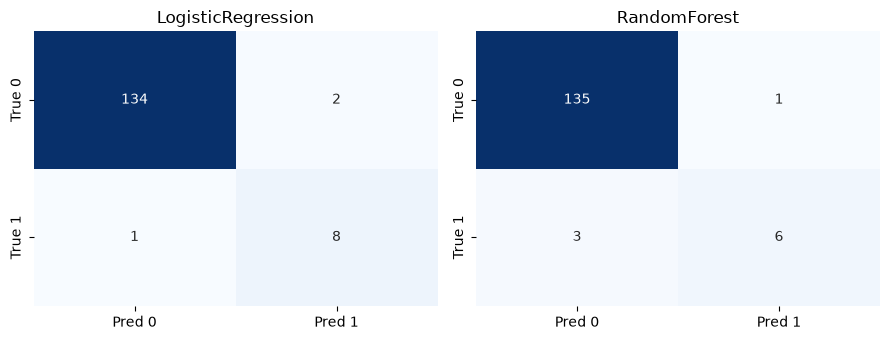

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
for a, cm, t in zip(ax, [cm_lr, cm_rf], ['LogisticRegression', 'RandomForest']):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=a,
                xticklabels=['Pred 0','Pred 1'], yticklabels=['True 0','True 1'])
    a.set_title(t)
plt.tight_layout(); plt.show()

### [2-7] 두 모델의 confusion matrix에서 전설 클래스(1)의 **오분류 패턴**을 분석하시오.

In [16]:
cols = ['Name','isLegendary','HP','Attack','Defense','Sp_Atk','Sp_Def','Speed','Total','Catch_Rate','hasGender']
for name, p in [('LogisticRegression', pred_lr), ('RandomForest', pred_rf)]:
    cm = confusion_matrix(y_test, p)
    print(f'[{name}] 전설인데 아니라고 함(FN): {cm[1,0]} / 전설 아닌데 전설이라 함(FP): {cm[0,1]}')
    display(df.loc[y_test.index[p != y_test.values], cols])

[LogisticRegression] 전설인데 아니라고 함(FN): 1 / 전설 아닌데 전설이라 함(FP): 2


,Name,isLegendary,HP,Attack,Defense,Sp_Atk,Sp_Def,Speed,Total,Catch_Rate,hasGender
375,Metagross,False,80,135,130,95,90,70,600,3,False
384,Jirachi,True,100,100,100,100,100,100,600,3,False
250,Celebi,False,100,100,100,100,100,100,600,45,False


[RandomForest] 전설인데 아니라고 함(FN): 3 / 전설 아닌데 전설이라 함(FP): 1


,Name,isLegendary,HP,Attack,Defense,Sp_Atk,Sp_Def,Speed,Total,Catch_Rate,hasGender
490,Darkrai,True,70,90,90,135,90,125,600,3,False
379,Latias,True,80,80,90,110,130,110,600,3,True
487,Cresselia,False,120,70,120,75,130,85,600,3,True
491,Shaymin,True,100,100,100,100,100,100,600,45,False


**5. 각 문항에서 "기술하시오"로 요구한 답변**
| 모델 | 전설인데 아니라고 한 경우(FN) | 전설이 아닌데 전설이라고 한 경우(FP) |
|---|---|---|
| LogisticRegression | 1 (Jirachi) | 2 (Metagross, Celebi) |
| RandomForest | 3 (Darkrai, Latias, Shaymin) | 1 (Cresselia) |

**특징:** 틀린 포켓몬은 모두 `Total` 600이고, 대부분 포획률 3·성별 없음 등 전설다운 특징을 공유한다. **Metagross(일반 600족)**, **Celebi·Jirachi·Darkrai·Shaymin(환상 포켓몬)**, **Cresselia(데이터상 일반으로 분류)** 처럼 전설과 일반의 경계에 있는 포켓몬이라 능력치·속성만으로는 구분이 어렵다.

### [2-8] 두 모델의 성능을 표로 정리하고, 성능 목표 달성 여부를 확인하시오.

In [17]:
res = pd.DataFrame({'모델': ['Baseline(전부 0)', 'LogisticRegression', 'RandomForestClassifier'],
                    'accuracy': [round(accuracy_score(y, base), 2), acc_lr, acc_rf],
                    'F1': [0.0, f1_lr, f1_rf]})
res['목표 달성(acc≥0.95, F1≥0.60)'] = ['-'] + ['달성 O' if a >= 0.95 and f >= 0.60 else '미달성 X' for a, f in zip([acc_lr, acc_rf], [f1_lr, f1_rf])]
res

,모델,accuracy,F1,"목표 달성(acc≥0.95, F1≥0.60)"
0,Baseline(전부 0),0.94,0.00,-
1,LogisticRegression,0.98,0.84,달성 O
2,RandomForestClassifier,0.97,0.75,달성 O


**5. 각 문항에서 "기술하시오"로 요구한 답변**\
| 모델 | accuracy | F1 | 목표 달성 |
|---|---|---|---|
| Baseline | 0.94 | 0.00 | - |
| LogisticRegression | 0.98 | 0.84 | O 달성 |
| RandomForestClassifier | 0.97 | 0.75 | O 달성 |

**기준선과 비교:** accuracy는 0.94 → 0.97~0.98로 소폭 올랐지만, F1이 0 → 0.75~0.84로 크게 올랐다. 기준선은 전설을 하나도 못 찾았지만 두 모델은 검증 데이터의 전설 9마리 중 6~8마리를 찾아냈으므로 의미 있게 학습했다고 볼 수 있다.

**더 좋은 모델과 이유:** 이번 결과에서는 LogisticRegression이 더 좋았습니다(F1 0.84 vs 0.75). 전설 여부는 능력치가 높고 포획률이 낮고 성별이 없다 처럼 각 특징의 크기에 비례하는 단순한 경향으로 잘 설명되어 선형 모델에 잘 맞고, 스케일링으로 특징들을 공정하게 반영했기 때문이다. 반면 RandomForest는 전설 학습 샘플이 37개뿐이라 경계에 있는 포켓몬을 다수(일반) 쪽으로 판단하는 경향이 있었다. 다만 검증 전설이 9마리뿐이라 한두 마리 차이로 결과가 바뀔 수 있다는 점은 감안해야 한다.